<div style="display: flex; background-color: RGB(255,114,0);" >
<h1 style="margin: auto; padding: 30px; ">ANALYSE DU STOCK ET DES VENTES DU SITE BOTTLENECK</h1>
</div>

# OBJECTIF DE CE NOTEBOOK

Bienvenue dans l'outil plébiscité par les analystes de données Jupyter.

Il s'agit d'un outil permettant de mixer et d'alterner code, texte et graphiques.

Cet outil est formidable pour plusieurs raisons:

+ Il permet de tester des lignes de codes au fur et à mesure de votre rédaction, de constater immédiatement le résultat d'une instruction, de la corriger si nécessaire.
+ Il permet aussi de rédiger du texte pour expliquer l'approche suivie ou les résultats d'une analyse et de le mettre en forme grâce à du code html ou plus simple avec **Markdown**
+ Il est possible d'ajouter des graphiques

Pour vous aider dans vos premiers pas à l'usage de Jupyter et de Python, nous avons rédigé ce notebook en vous indiquant les instructions à suivre.

Il vous suffit pour cela de saisir le code Python répondant à l'instruction donnée.

Vous verrez de temps à autre le code Python répondant à une instruction donnée mais cela est fait pour vous aider à comprendre la nature du travail qui vous est demandé.

Et gardez à l'esprit qu'il n'y a pas de solution unique pour résoudre un problème et qu'il y a autant de résolutions de problèmes que de développeurs ;)...



<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Importation des librairies</h3>
</div>

In [1]:
#Importation de la librairie Pandas

import pandas as pd

In [2]:
#Importation de la librairie plotly express

import plotly.express as px

In [3]:
#Trouver dans Google l'instruction permettant d'afficher toutes les colonnes d'un dataframe
#Saisir dans Google les mots clés "display all columns dataframe Pandas" par exemple.
#Dans les résultats de la recherche, privilégier les solutions provenant de Stack Overflow ou Medium

pd.set_option('display.max_columns', None)

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Chargements des fichiers</h3>
</div>

In [4]:
#Importation du fichier web.xlsx
df_web = pd.read_excel("web.xlsx")

#Importation du fichier erp.xlsx
df_erp = pd.read_excel("erp.xlsx")

#Importation du fichier liaison.xlsx
df_liaison = pd.read_excel("liaison.xlsx")

C:\Users\Ced\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():
C:\Users\Ced\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():
C:\Users\Ced\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - Analyse exploratoire du fichier erp.xlsx</h3>
</div>

In [5]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(df_erp.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_erp.shape[1]))

Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 6 colonne(s)


In [6]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes

df_erp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      825 non-null    int64  
 1   onsale_web      825 non-null    int64  
 2   price           825 non-null    float64
 3   stock_quantity  825 non-null    int64  
 4   stock_status    825 non-null    object 
 5   purchase_price  825 non-null    float64
dtypes: float64(2), int64(3), object(1)
memory usage: 38.8+ KB


In [7]:
#Afficher les 5 premières lignes de la table

df_erp.head(5)

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,4352,1,225.0,0,outofstock,137.81
1,5001,1,217.5,18,instock,116.87
2,5892,1,191.3,98,instock,116.06
3,4402,1,176.0,11,instock,78.25
4,5767,1,175.0,12,instock,90.42


In [8]:
#Vérifier si il y a des lignes en doublon dans la colonne product_id

print("-Nombre de lignes en doublon dans la colonne product_id:",df_erp.product_id.duplicated().sum())

-Nombre de lignes en doublon dans la colonne product_id: 0


In [9]:
#Afficher les valeurs distinctes de la colonne stock_status

print("-Valeurs distinctes de la colonne stock_status")
print(df_erp['stock_status'].value_counts().sort_index())


#À quelle(s) autre(s) colonne(s) sont-elles liées ?

## les valeurs sont liées à la colonne stock_quantity

-Valeurs distinctes de la colonne stock_status
stock_status
instock       733
outofstock     92
Name: count, dtype: int64


In [10]:
#Création d'une colonne "stock_status_2"
#La valeur de cette deuxième colonne sera fonction de la valeur dans la colonne "stock_quantity"
#Si la valeur de la colonne "stock_quantity" est nulle, renseigner "outofstock" sinon mettre "instock"

df_erp['stock_status_2'] = df_erp['stock_quantity'].apply(lambda x: "outofstock" if x <= 0 else "instock")
df_erp

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
0,4352,1,225.0,0,outofstock,137.81,outofstock
1,5001,1,217.5,18,instock,116.87,instock
2,5892,1,191.3,98,instock,116.06,instock
3,4402,1,176.0,11,instock,78.25,instock
4,5767,1,175.0,12,instock,90.42,instock
...,...,...,...,...,...,...,...
820,5777,1,5.7,51,instock,3.03,instock
821,6129,1,5.2,68,instock,2.74,instock
822,5017,0,-8.0,0,outofstock,4.34,outofstock
823,6594,0,-9.1,19,instock,4.61,instock


In [11]:
#Vérifions que les 2 colonnes sont identiques:
#Les 2 colonnes sont strictement identiques si les valeurs de chaque ligne sont strictement identiques 2 à 2
#La comparaison de 2 colonnes peut se réaliser simplement avec l'instruction ci-dessous:

#df_erp["stock_status"] == df_erp["stock_status_2"]

#Le résultat est l'affichage de True ou False pour chacune des lignes du dataset
#C'est un bon début, mais difficile à exploiter

df_erp["bolean_stock_status_2"] = df_erp["stock_status"] == df_erp["stock_status_2"]
df_erp

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2,bolean_stock_status_2
0,4352,1,225.0,0,outofstock,137.81,outofstock,True
1,5001,1,217.5,18,instock,116.87,instock,True
2,5892,1,191.3,98,instock,116.06,instock,True
3,4402,1,176.0,11,instock,78.25,instock,True
4,5767,1,175.0,12,instock,90.42,instock,True
...,...,...,...,...,...,...,...,...
820,5777,1,5.7,51,instock,3.03,instock,True
821,6129,1,5.2,68,instock,2.74,instock,True
822,5017,0,-8.0,0,outofstock,4.34,outofstock,True
823,6594,0,-9.1,19,instock,4.61,instock,True


In [12]:
#Mais il est possible de synthétiser ce résultat en effectuant la somme de cette colonne:
#True vaut 1 et False 0
#Nous devrions obtenir la somme de 824 qui correspond au nombre de lignes dans ce dataset

sum_bolean_stock_status_2 = df_erp["bolean_stock_status_2"].sum()

print("-Nombre de lignes avec statut stock correspondant:", sum_bolean_stock_status_2)
print("-Nombre de lignes en écart:", len(df_erp)-sum_bolean_stock_status_2)


-Nombre de lignes avec statut stock correspondant: 823
-Nombre de lignes en écart: 2


In [13]:
#Si les colonnes ne sont absolument pas identiques ligne à ligne alors identifier la ligne en écart
##Dans ce cas je vous donne ce lien pour apprendre à réaliser des filtres dans Pandas:
##https://bitbucket.org/hrojas/learn-pandas/src/master/
##Lesson 3

In [14]:
#Corriger la ou les données incohérentes

df_erp['stock_status'] = df_erp['stock_quantity'].apply(lambda x: "outofstock" if x <= 0 else "instock")

#Vérification en utilisant le même code que plus haut pour afficher les problèmes

df_erp["bolean_stock_status_2"] = df_erp["stock_status"] == df_erp["stock_status_2"]

sum_bolean_stock_status_2 = df_erp["bolean_stock_status_2"].sum()

print("-Nombre de lignes avec statut stock correspondant:", sum_bolean_stock_status_2)
print("-Nombre de lignes en écart:", len(df_erp)-sum_bolean_stock_status_2)

-Nombre de lignes avec statut stock correspondant: 825
-Nombre de lignes en écart: 0


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1 - Analyse exploratoire de chaque variable du fichier erp.xlsx</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.1 - Analyse de la variable PRIX</h3>
</div>

In [15]:
###############
## LES PRIX  ##
###############

#Vérification des prix: Y a t-il des prix non renseignés, négatifs ou nuls?

#Afficher le ou les prix non renseignés dans la colonne "price"

print("Nombres d'articles avec un prix non renseigné: {}".format( df_erp["price"].isnull().sum() )) #Saisir l'instruction manquante dans la fonction format
         
#Afficher le prix minimum de la colonne "price"

price_min = df_erp["price"].min()

#Afficher le prix maximum de la colonne "price"

price_max = df_erp["price"].max()

#Afficher les prix inférieurs à 0 (qu'est-ce qu'il faut en faire ?)

price_negatif = df_erp[df_erp["price"] < 0]
price_negatif = price_negatif[['product_id','price','purchase_price','stock_quantity','stock_status']]
nb_price_negatif = len(price_negatif)

print("-Prix minimum:", price_min)
print("-Prix maximum:", price_max)

print("\n-Nombre de lignes ayant un prix négatif:", nb_price_negatif)
print("-Lignes ayant un prix négatif: \n", price_negatif)

## le service commercial doit être prévenu des anomalies de prix
## il faut mettre en place une condition de blocage des données négatives pour la variable prix dans l'ERP
## il faut modifier le prix pour neutraliser le signe négatif avec une multiplication par -1 ou supprimer les lignes de l'analyse


Nombres d'articles avec un prix non renseigné: 0
-Prix minimum: -20.0
-Prix maximum: 225.0

-Nombre de lignes ayant un prix négatif: 3
-Lignes ayant un prix négatif: 
      product_id  price  purchase_price  stock_quantity stock_status
822        5017   -8.0            4.34               0   outofstock
823        6594   -9.1            4.61              19      instock
824        4233  -20.0           10.33               0   outofstock


In [16]:
## modification prix négatifs

#df_erp['price'] = df_erp['price'].abs()

#price_negatif = df_erp[df_erp["price"] < 0]
#price_negatif = price_negatif[['product_id','price','purchase_price']]
#nb_price_negatif = len(price_negatif)

#print("\n-Nombre de lignes ayant un prix négatif:", nb_price_negatif)
#print("-Lignes ayant un prix négatif: \n", price_negatif)

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.2 - Analyse de la variable STOCK</h3>
</div>

In [17]:
#######################
### stock_quantity  ###
#######################

#Vérification de la colonne stock quantity
#Afficher la quantité minimum de la colonne "stock_quantity"

stock_min = df_erp["stock_quantity"].min()

#Afficher la quantité maximum de la colonne "stock_quantity"

stock_max = df_erp["stock_quantity"].max()

#Afficher les stocks inférieurs à 0 (qu'est-ce qu'il faut en faire ?)

stock_negatif = df_erp[df_erp["stock_quantity"] < 0]
stock_negatif = stock_negatif[['product_id','stock_quantity','stock_status']]
nb_stock_negatif = len(stock_negatif)

print("-Stock minimum:", stock_min)
print("-Stock maximum:", stock_max)

print("\n-Nombre de lignes ayant un stock négatif:", nb_stock_negatif)
print("-Lignes ayant un stock négatif:\n", stock_negatif)

## le service commercial et logistique doit être prévenu des anomalies de stock
## il faut mettre en place une condition de blocage des données négatives pour la variable stock dans l'ERP
## il faut modifier le stock pour le mettre à 0 ou supprimer les lignes de l'analyse


-Stock minimum: -10
-Stock maximum: 145

-Nombre de lignes ayant un stock négatif: 2
-Lignes ayant un stock négatif:
      product_id  stock_quantity stock_status
186        5700              -1   outofstock
744        4973             -10   outofstock


In [18]:
## modification stock négatifs

#df_erp['stock_quantity'] = df_erp['stock_quantity'].clip(lower=0).fillna(0)

#stock_negatif = df_erp[df_erp["stock_quantity"] < 0]
#stock_negatif = stock_negatif[['product_id','stock_quantity','stock_status']]
#nb_stock_negatif = len(stock_negatif)

#print("\n-Nombre de lignes ayant un stock négatif:", nb_stock_negatif)
#print("-Lignes ayant un stock négatif:\n", stock_negatif)

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.3 - Analyse de la variable ONSALE_WEB</h3>
</div>

In [19]:
#Vérification de la colonne onsale_web et des valeurs qu'elle contient. Que signifient-elles?

df_erp['onsale_web'].value_counts().sort_index()

onsale_web
0    109
1    716
Name: count, dtype: int64

In [20]:
#Quelles sont les colonnes à conserver selon vous?

""" Sur le fichier erp, toutes les colonnes sont à conserver car elles peuvent être utiles pour information ou analyse, à part la colonne stock_status_2 en doublons """

' Sur le fichier erp, toutes les colonnes sont à conserver car elles peuvent être utiles pour information ou analyse, à part la colonne stock_status_2 en doublons '

In [21]:
#Supprimer la colonne comportant le libellé "stock_status_2" car elle est redondante 
#avec la colonne "stock_status".

df_erp = df_erp.drop('stock_status_2', axis=1)
df_erp = df_erp.drop('bolean_stock_status_2', axis=1)

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.4 - Analyse de la variable prix d'achat</h3>
</div>

In [22]:
######################
##   prix d'achat   ##
######################

#Vérification de la colonne purchase_price : 
#Afficher le ou les prix non renseignés dans la colonne "purchase_price"

purchase_price_null = df_erp[df_erp["purchase_price"].isnull()]
nb_purchase_price_null = len(purchase_price_null)

#Afficher le prix minimum de la colonne "purchase_price"

purchase_price_min = df_erp["purchase_price"].min()

#Afficher le prix maximum de la colonne "purchase_price"

purchase_price_max = df_erp["purchase_price"].max()

print("-Nombre de lignes ayant un prix achat non renseigné:", nb_purchase_price_null)
print("-Lignes ayant un prix achat non renseigné:", purchase_price_null)
print("\n-Prix achat minimum:", purchase_price_min)
print("-Prix achat maximum:", purchase_price_max)

-Nombre de lignes ayant un prix achat non renseigné: 0
-Lignes ayant un prix achat non renseigné: Empty DataFrame
Columns: [product_id, onsale_web, price, stock_quantity, stock_status, purchase_price]
Index: []

-Prix achat minimum: 2.74
-Prix achat maximum: 137.81


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Analyse exploratoire du fichier web.xlsx</h3>
</div>
 

In [23]:
#Dimension du dataset
#Nombre d'observations
#Nombre de caractéristiques

df_web.shape

## le tableau comporte 1513 lignes et 29 colonnes

(1513, 29)

In [24]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes

df_web.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   sku                    1428 non-null   object        
 1   virtual                1513 non-null   int64         
 2   downloadable           1513 non-null   int64         
 3   rating_count           1513 non-null   int64         
 4   average_rating         1430 non-null   float64       
 5   total_sales            1430 non-null   float64       
 6   tax_status             716 non-null    object        
 7   tax_class              0 non-null      float64       
 8   post_author            1430 non-null   float64       
 9   post_date              1430 non-null   datetime64[ns]
 10  post_date_gmt          1430 non-null   datetime64[ns]
 11  post_content           0 non-null      float64       
 12  product_type           1429 non-null   object        
 13  pos

In [25]:
#Selon vous, quelles sont les colonnes à conserver ?

""" les colonnes à conserver sont celles dont les données ne sont pas à zéro et comportant des données pertinentes pour l'analyse """

" les colonnes à conserver sont celles dont les données ne sont pas à zéro et comportant des données pertinentes pour l'analyse "

In [26]:
#Si vous avez défini des colonnes à supprimer, effectuer l'opération

#df_web = df_web.drop(['virtual','downloadable','rating_count','average_rating','tax_status','tax_class','post_author','post_date_gmt','post_content','post_status','comment_status','ping_status','post_password','post_modified_gmt','post_content_filtered','post_parent','menu_order','comment_count'], axis=1)

df_web = df_web[['sku','total_sales','product_type','post_title','post_name','post_type']]
df_web             

,sku,total_sales,product_type,post_title,post_name,post_type
0,38,10.0,Vin,Emile Boeckel Crémant Brut Blanc de Blancs,emile-boeckel-cremant-brut-blanc-de-blancs,attachment
1,38,10.0,Vin,Emile Boeckel Crémant Brut Blanc de Blancs,emile-boeckel-cremant-brut-blanc-de-blancs,product
2,41,6.0,Vin,Marcel Windholtz Eau de Vie de Marc de Gewurzt...,marcel-windholtz-eau-de-marc-de-gewurztraminer,product
3,41,6.0,Vin,Marcel Windholtz Eau de Vie de Marc de Gewurzt...,marcel-windholtz-eau-de-marc-de-gewurztraminer,attachment
4,304,8.0,Champagne,Champagne Gosset Grande Réserve,gosset-champagne-grande-reserve,attachment
...,...,...,...,...,...,...
1508,NaN,NaN,NaN,NaN,NaN,NaN
1509,NaN,NaN,NaN,NaN,NaN,NaN
1510,NaN,NaN,NaN,NaN,NaN,NaN
1511,NaN,NaN,NaN,NaN,NaN,NaN


In [27]:
#Visualisation des valeurs de la colonne sku
#Quelles sont les valeurs qui ne semblent pas respecter la régle de codification?

sku_values = df_web['sku'].unique()
sku_values

## les valeurs qui ne respectent pas le format sont celles qui comportent des caractères non numériques

array([38, 41, 304, 523, 531, 791, 793, 798, 802, 804, 805, 807, 812,
       1360, 1364, 1366, 1662, 2179, 2361, 2534, 3383, 3506, 3507, 3509,
       3510, 3568, 4679, 5646, 6616, 7032, 7033, 7086, 7818, 7819, 8193,
       8344, 8365, 8463, 9562, 9636, 9937, 10014, 10459, 10775, 10814,
       11049, 11225, 11258, 11277, 11467, 11585, 11586, 11587, 11601,
       11602, 11641, 11668, 11669, 11736, 11847, 11849, 11862, 11933,
       11996, 11997, 12045, 12194, 12203, 12315, 12339, 12365, 12366,
       12476, 12494, 12496, 12585, 12586, 12587, 12588, 12589, 12599,
       12639, 12640, 12641, 12657, 12771, 12790, 12791, 12857, 12869,
       12881, 12882, 12942, 13032, 13052, 13072, 13073, 13074, 13078,
       13089, 13096, 13117, 13127, 13172, 13209, 13211, 13215, 13217,
       13230, 13291, 13313, 13379, 13412, 13416, 13435, 13453, 13460,
       13514, 13515, 13516, 13517, 13520, 13531, 13557, 13567, 13572,
       13599, 13604, 13627, 13647, 13659, 13662, 13736, 13754, 13762,
       13765,

In [28]:
#Si vous avez identifié des codes articles ne respectant pas la régle de codification, consultez-les

row_non_numeric = df_web[~ df_web["sku"].str.isnumeric().fillna(True)]["sku"].unique()
row_non_numeric

## nous avons deux codes articles non numériques : '13127-1', 'bon-cadeau-25-euros'

C:\Users\Ced\AppData\Local\Temp\ipykernel_11836\2148680276.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  row_non_numeric = df_web[~ df_web["sku"].str.isnumeric().fillna(True)]["sku"].unique()


array(['13127-1', 'bon-cadeau-25-euros'], dtype=object)

In [29]:
## modification sku pour format numérique

df_web["sku"] = df_web.sku.replace('13127-1', '13128')
df_web["sku"] = df_web.sku.replace('bon-cadeau-25-euros', '99999')
df_web["sku"] = pd.to_numeric(df_web["sku"], errors='coerce')
#df_web

In [30]:
#Identifier les lignes sans code article

df_web_sku_nan = df_web[df_web["sku"].isnull()]
df_web_sku_nan

,sku,total_sales,product_type,post_title,post_name,post_type
1428,NaN,NaN,NaN,NaN,NaN,NaN
1429,NaN,NaN,NaN,NaN,NaN,NaN
1430,NaN,NaN,NaN,NaN,NaN,NaN
1431,NaN,NaN,NaN,NaN,NaN,NaN
1432,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...
1508,NaN,NaN,NaN,NaN,NaN,NaN
1509,NaN,NaN,NaN,NaN,NaN,NaN
1510,NaN,NaN,NaN,NaN,NaN,NaN
1511,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
#Pour les codes articles identifiés, réaliser une analyse et définir l'action à entreprendre

## les lignes sans code article n'ont pas de données, elles peuvent être supprimée

df_web = df_web[df_web["sku"].notnull()]
df_web

,sku,total_sales,product_type,post_title,post_name,post_type
0,38.0,10.0,Vin,Emile Boeckel Crémant Brut Blanc de Blancs,emile-boeckel-cremant-brut-blanc-de-blancs,attachment
1,38.0,10.0,Vin,Emile Boeckel Crémant Brut Blanc de Blancs,emile-boeckel-cremant-brut-blanc-de-blancs,product
2,41.0,6.0,Vin,Marcel Windholtz Eau de Vie de Marc de Gewurzt...,marcel-windholtz-eau-de-marc-de-gewurztraminer,product
3,41.0,6.0,Vin,Marcel Windholtz Eau de Vie de Marc de Gewurzt...,marcel-windholtz-eau-de-marc-de-gewurztraminer,attachment
4,304.0,8.0,Champagne,Champagne Gosset Grande Réserve,gosset-champagne-grande-reserve,attachment
...,...,...,...,...,...,...
1423,19822.0,1.0,Vin,Tempier Bandol Cabassaou 2017,tempier-bandol-cabassaou-2017,attachment
1424,13128.0,4.0,Vin,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,clos-du-mont-olivet-chateauneuf-du-pape-2007-2,product
1425,13128.0,4.0,Vin,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,clos-du-mont-olivet-chateauneuf-du-pape-2007-2,attachment
1426,99999.0,7.0,Autre,Bon cadeau de 25€,bon-cadeau-de-25-euros,attachment


In [32]:
df_web.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1428 entries, 0 to 1427
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sku           1428 non-null   float64
 1   total_sales   1428 non-null   float64
 2   product_type  1427 non-null   object 
 3   post_title    1428 non-null   object 
 4   post_name     1428 non-null   object 
 5   post_type     1428 non-null   object 
dtypes: float64(2), object(4)
memory usage: 78.1+ KB


In [33]:
#La clé pour chaque ligne est-elle unique? autrement dit, y a-t-il des doublons?

# la colonne sku est constituée de doublons, chaque code a deux lignes : une pour la fiche produit et une pour le visuel

print("-Nombre de doublons dans la colonne sku:",df_web.sku.duplicated().sum())

-Nombre de doublons dans la colonne sku: 714


In [34]:
#Les lignes sans code article semblent être toutes non renseignées
#Pour s'en assurer, réaliser les étapes suivantes:
#1 - Créer un dataframe avec uniquement les lignes sans code article

#df_sku_nan = df_web_null[df_web_null["sku"].isnull()]
df_web_sku_nan

#2 - Utiliser la fonction df.info() sur ce nouveau dataframe pour observer le nombre de valeurs renseignées dans chacune des colonnes

df_web_sku_nan.info()

#3 - Que constatez-vous?

""" 
il y a deux lignes dont les skus ne sont pas renseignés qui ont des données
ces deux produits ne seront pas inclus dans un fichier fusionné car ils n'ont pas de sku pour faire les jointures
"""

<class 'pandas.core.frame.DataFrame'>
Index: 85 entries, 1428 to 1512
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sku           0 non-null      float64
 1   total_sales   2 non-null      float64
 2   product_type  2 non-null      object 
 3   post_title    2 non-null      object 
 4   post_name     2 non-null      object 
 5   post_type     2 non-null      object 
dtypes: float64(2), object(4)
memory usage: 4.6+ KB


" \n\nil y a deux lignes dont les skus ne sont pas renseignés qui ont des données\nces deux produits ne seront pas inclus dans un fichier fusionné car ils n'ont pas de sku pour faire les jointures\n\n"

In [35]:
df_web_sku_nan = df_web_sku_nan[df_web_sku_nan['post_title'].notnull()]
df_web_sku_nan

## ces deux lignes ont des données de ventes en négatif
## elles n'ont pas de product_id ni de web_id
## nous les excluons de l'analyse en raison de ces erreurs multiples

,sku,total_sales,product_type,post_title,post_name,post_type
1493,NaN,-56.0,Vin,Pierre Jean Villa Condrieu Jardin Suspendu 2018,pierre-jean-villa-condrieu-suspendu-2018,product
1495,NaN,-17.0,Vin,Pierre Jean Villa Côte Rôtie Fongeant 2017,pierre-jean-villa-cote-rotie-fongeant-2017,product


In [36]:
## Nous supprimons les doublons de la colonne sku en sélectionnant les lignes "produit" de la colonne post_type 

df_web = df_web[df_web["post_type"] == 'product']
df_web = df_web.drop('post_type', axis=1)
df_web

,sku,total_sales,product_type,post_title,post_name
1,38.0,10.0,Vin,Emile Boeckel Crémant Brut Blanc de Blancs,emile-boeckel-cremant-brut-blanc-de-blancs
2,41.0,6.0,Vin,Marcel Windholtz Eau de Vie de Marc de Gewurzt...,marcel-windholtz-eau-de-marc-de-gewurztraminer
5,304.0,8.0,Champagne,Champagne Gosset Grande Réserve,gosset-champagne-grande-reserve
6,523.0,0.0,Cognac,Cognac Normandin Mercier VFC,cognac-normandin-mercier-vfc
9,531.0,8.0,Champagne,Champagne Petit Lebrun &amp; Fils Blanc de Bla...,champagne-petit-lebrun-fils-blanc-de-blancs-gr...
...,...,...,...,...,...
1418,19820.0,6.0,Vin,Tempier Bandol Migoua 2017,tempier-bandol-migoua-2017
1421,19821.0,8.0,Vin,Tempier Bandol Tourtine 2017,tempier-bandol-tourtine-2017
1422,19822.0,1.0,Vin,Tempier Bandol Cabassaou 2017,tempier-bandol-cabassaou-2017
1424,13128.0,4.0,Vin,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,clos-du-mont-olivet-chateauneuf-du-pape-2007-2


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3 - Analyse exploratoire du fichier liaison.xlsx</h3>
</div>

In [37]:
#Dimension du dataset
#Nombre d'observations
#Nombre de caractéristiques

df_liaison.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      734 non-null    object
 1   product_id  825 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 13.0+ KB


In [38]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes

df_liaison.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      734 non-null    object
 1   product_id  825 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 13.0+ KB


In [39]:
#Les valeurs de la colonne "product_id" sont-elles toutes uniques?

## il n'y a pas de doublons dans la colonne "product_id"

print("-Nombre de lignes en doublon dans la colonne product_id:",df_liaison.product_id.duplicated().sum())

-Nombre de lignes en doublon dans la colonne product_id: 0


In [40]:
#Les valeurs de la colonne "id_web" sont-elles toutes uniques?

df_liaison_notnan = df_liaison[df_liaison["id_web"].notnull()]

## il n'y a pas de doublons dans la colonne "id_web"

print("-Nombre de lignes en doublon dans la colonne id_web:",df_liaison_notnan.id_web.duplicated().sum())

-Nombre de lignes en doublon dans la colonne id_web: 0


In [41]:
#Avons-nous des articles sans correspondance?

df_liaison[df_liaison["id_web"].isnull()]

## il y a 91 lignes avec un product_id sans id_web

,id_web,product_id
19,NaN,4055
49,NaN,4090
50,NaN,4092
119,NaN,4195
131,NaN,4209
...,...,...
817,NaN,7196
818,NaN,7200
819,NaN,7201
820,NaN,7203


In [42]:
## Nous faisons la modification des id_web non numériques 

df_liaison["id_web"] = df_liaison.id_web.replace('13127-1', '13128')
df_liaison["id_web"] = df_liaison.id_web.replace('14680-1', '14681')
df_liaison["id_web"] = df_liaison.id_web.replace('bon-cadeau-25-euros', '99999')
df_liaison["id_web"] = pd.to_numeric(df_liaison["id_web"], errors='coerce')
df_liaison

,id_web,product_id
0,15298.0,3847
1,15296.0,3849
2,15300.0,3850
3,19814.0,4032
4,19815.0,4039
...,...,...
820,NaN,7203
821,NaN,7204
822,13128.0,7247
823,14681.0,7329


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jonction des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.1 - Jonction du fichier df_erp et df_liaison</h3>
</div>

In [43]:
#Fusion des fichiers df_erp et df_liaison

df_merge = pd.merge(df_erp,df_liaison, on="product_id", how="left")
df_merge

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web
0,4352,1,225.0,0,outofstock,137.81,15940.0
1,5001,1,217.5,18,instock,116.87,14581.0
2,5892,1,191.3,98,instock,116.06,14983.0
3,4402,1,176.0,11,instock,78.25,3510.0
4,5767,1,175.0,12,instock,90.42,15185.0
...,...,...,...,...,...,...,...
820,5777,1,5.7,51,instock,3.03,14338.0
821,6129,1,5.2,68,instock,2.74,14570.0
822,5017,0,-8.0,0,outofstock,4.34,NaN
823,6594,0,-9.1,19,instock,4.61,NaN


In [44]:
#df_merge.to_excel("df_jonction1.xlsx")

In [45]:
#Y a t-il des lignes ne "matchant" pas entre les 2 fichiers?

## il n'y a aucune ligne ne matchant pas entre les deux fichiers : les 825 lignes product_id sont présentes en totalité

In [46]:
df_erp = df_erp.sort_values(by=['product_id'])
df_erp = df_erp.reset_index(drop=True)
df_liaison = df_liaison.sort_values(by=['product_id'])
df_liaison = df_liaison.reset_index(drop=True)

In [47]:
df_verif_jonction1 = pd.DataFrame()
df_verif_jonction1['code_erp'] = df_erp['product_id']
df_verif_jonction1['code_liaison'] = df_liaison['product_id']
df_verif_jonction1['code_match'] = ( df_verif_jonction1['code_erp'] == df_verif_jonction1['code_liaison'])
df_verif_jonction1

,code_erp,code_liaison,code_match
0,3847,3847,True
1,3849,3849,True
2,3850,3850,True
3,4032,4032,True
4,4039,4039,True
...,...,...,...
820,7203,7203,True
821,7204,7204,True
822,7247,7247,True
823,7329,7329,True


In [48]:
df_verif_jonction1['code_match'].value_counts().sort_index()

## les 825 lignes des fichiers ERP et liaison matchent entre elles

code_match
True    825
Name: count, dtype: int64

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.2 - Jonction du fichier df_merge et df_web</h3>
</div>

In [49]:
#Fusionner les datasets df_merge et df_web

df_web = df_web.rename(columns={'sku': 'id_web'})
df_merge = pd.merge(df_merge,df_web, on="id_web", how="left")
df_merge = df_merge.reset_index(drop=True)
df_merge

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,total_sales,product_type,post_title,post_name
0,4352,1,225.0,0,outofstock,137.81,15940.0,11.0,Champagne,Champagne Egly-Ouriet Grand Cru Millésimé 2008,champagne-egly-ouriet-grand-cru-millesime-2008
1,5001,1,217.5,18,instock,116.87,14581.0,2.0,Vin,David Duband Charmes-Chambertin Grand Cru 2014,david-duband-charmes-chambertin-grand-cru-2014
2,5892,1,191.3,98,instock,116.06,14983.0,6.0,Champagne,Coteaux Champenois Egly-Ouriet Ambonnay Rouge ...,coteaux-champenois-egly-ouriet-ambonnay-rouge-...
3,4402,1,176.0,11,instock,78.25,3510.0,3.0,Cognac,Cognac Frapin VIP XO,cognac-frapin-vip-xo
4,5767,1,175.0,12,instock,90.42,15185.0,4.0,Vin,Camille Giroud Clos de Vougeot 2016,camille-giroud-clos-de-vougeot-2016
...,...,...,...,...,...,...,...,...,...,...,...
820,5777,1,5.7,51,instock,3.03,14338.0,16.0,Vin,Maurel Pays d'Oc Cabernet-Sauvignon 2017,maurel-pays-d-oc-cabernet-sauvignon-2017
821,6129,1,5.2,68,instock,2.74,14570.0,20.0,Vin,Moulin de Gassac IGP Pays d'Hérault Guilhem Bl...,moulin-de-gassac-igp-pays-dherault-guilhem-bla...
822,5017,0,-8.0,0,outofstock,4.34,NaN,NaN,NaN,NaN,NaN
823,6594,0,-9.1,19,instock,4.61,NaN,NaN,NaN,NaN,NaN


In [50]:
#df_merge.to_excel("df_jonction2.xlsx")

In [51]:
#Avons-nous des lignes sans correspondance?

""" 
Nous avons des lignes sans correspondance dans les fichier ERP et dans le fichier WEB :

Il y a 825 codes produits dans le fichier ERP, nous retrouvons 714 codes dans le fichier web
Nous avons 734 lignes qui correspondent au fichier ERP, soit 91 lignes de l'ERP sans id web
Nous avons 20 lignes supplémentaires du fichier liaison que nous ne retrouvons pas dans le fichier WEB
Il y a au total 111 lignes de l'ERP manquantes dans le fichier WEB

Il y a 716 codes web dans le fichier WEB, nous retrouvons 714 codes correspondants dans le fichier ERP
Nous avons 2 lignes produits dans le fichier WEB qui n'ont pas de correspondance dans l'ERP
Ces 2 lignes ont des anomalies de quantités de ventes qui sont négatives

"""

" \nNous avons des lignes sans correspondance dans les fichier ERP et dans le fichier WEB :\n\nIl y a 825 codes produits dans le fichier ERP, nous retrouvons 714 codes dans le fichier web\nNous avons 734 lignes qui correspondent au fichier ERP, soit 91 lignes de l'ERP sans id web\nNous avons 20 lignes supplémentaires du fichier liaison que nous ne retrouvons pas dans le fichier WEB\nIl y a au total 111 lignes de l'ERP manquantes dans le fichier WEB\n\nIl y a 716 codes web dans le fichier WEB, nous retrouvons 714 codes correspondants dans le fichier ERP\nNous avons 2 lignes produits dans le fichier WEB qui n'ont pas de correspondance dans l'ERP\nCes 2 lignes ont des anomalies de quantités de ventes qui sont négatives\n\n"

In [52]:
## verification jointures fichier erp

In [53]:
df_erp_verif = df_erp[['product_id']]
df_web_verif = df_web[['id_web']]
df_liaison_verif = df_liaison[['id_web','product_id']]
list_web_idweb = df_web['id_web']

In [54]:
df_merge_erp = pd.merge(df_erp_verif,df_liaison_verif, on="product_id", how="left")
df_merge_erp['verif_idweb'] = df_merge_erp.id_web.isin(list_web_idweb)
df_merge_erp

,product_id,id_web,verif_idweb
0,3847,15298.0,True
1,3849,15296.0,True
2,3850,15300.0,True
3,4032,19814.0,True
4,4039,19815.0,True
...,...,...,...
820,7203,NaN,False
821,7204,NaN,False
822,7247,13128.0,True
823,7329,14681.0,False


In [55]:
#df_merge_erp.info()

In [56]:
#df_merge_erp['id_web'].isna().sum()

In [57]:
df_merge_erp['verif_idweb'].value_counts().sort_index()

verif_idweb
False    111
True     714
Name: count, dtype: int64

In [58]:
### Liste des 111 codes présents dans l'ERP mais pas dans le fichier WEB

df_merge_erp_nan = df_merge_erp[df_merge_erp['verif_idweb'] == False]
df_merge_erp_nan

,product_id,id_web,verif_idweb
19,4055,NaN,False
49,4090,NaN,False
50,4092,NaN,False
119,4195,NaN,False
131,4209,NaN,False
...,...,...,...
818,7200,NaN,False
819,7201,NaN,False
820,7203,NaN,False
821,7204,NaN,False


In [59]:
## vérification jointures fichiers WEB

In [60]:
df_verif_web = df_web[['id_web','total_sales','product_type','post_title']]
df_verif_web

,id_web,total_sales,product_type,post_title
1,38.0,10.0,Vin,Emile Boeckel Crémant Brut Blanc de Blancs
2,41.0,6.0,Vin,Marcel Windholtz Eau de Vie de Marc de Gewurzt...
5,304.0,8.0,Champagne,Champagne Gosset Grande Réserve
6,523.0,0.0,Cognac,Cognac Normandin Mercier VFC
9,531.0,8.0,Champagne,Champagne Petit Lebrun &amp; Fils Blanc de Bla...
...,...,...,...,...
1418,19820.0,6.0,Vin,Tempier Bandol Migoua 2017
1421,19821.0,8.0,Vin,Tempier Bandol Tourtine 2017
1422,19822.0,1.0,Vin,Tempier Bandol Cabassaou 2017
1424,13128.0,4.0,Vin,Clos du Mont-Olivet Châteauneuf-du-Pape 2007


In [61]:
df_liaison_verif = df_liaison_verif.dropna()
#df_liaison_verif

In [62]:
## tableau des codes produits avec correspondance totale sur le fichier merge

df_merge_web = pd.merge(df_verif_web,df_liaison_verif, on="id_web", how="left")
df_merge_web = df_merge_web.sort_values(by=['product_id'])
df_merge_web = df_merge_web.reset_index(drop=True)
df_merge_web

,id_web,total_sales,product_type,post_title,product_id
0,15298.0,6.0,Vin,Pierre Jean Villa Saint-Joseph Préface 2018,3847
1,15296.0,9.0,Vin,Pierre Jean Villa Saint-Joseph Rouge Tildé 2017,3849
2,15300.0,0.0,Vin,Pierre Jean Villa Crozes-Hermitage Accroche Co...,3850
3,19814.0,12.0,Vin,Pierre Jean Villa IGP Collines Rhodaniennes Ga...,4032
4,19815.0,3.0,Vin,Pierre Jean Villa Côte Rôtie Carmina 2017,4039
...,...,...,...,...,...
709,16135.0,9.0,Vin,Mouthes Le Bihan Côtes de Duras L'Aimé Chai 2015,6930
710,15891.0,9.0,Vin,Camin Larredya Jurançon Sec La Virada 2018,7023
711,15887.0,5.0,Vin,Domaine Jamet Côte Rôtie Fructus Voluptas 2018,7025
712,13128.0,4.0,Vin,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,7247


In [63]:
## ces deux produits étaient présents dans le fichier WEB mais ne sont pas présent dans le fichier fusionnés car il n'ont pas de web_id
## les deux codes produits de ces lignes (product_id : 5070 et 5075 présents seulement dans la colonne guid) n'ont pas de correspondance dans le fichier de liaison
## les informations de ventes sont négatives et ne sont pas conformes
## ces deux lignes n'ont pas de données product_id ou web_id
## nous les excluons de l'analyse en raison de ces erreurs multiples

df_web_sku_nan

,sku,total_sales,product_type,post_title,post_name,post_type
1493,NaN,-56.0,Vin,Pierre Jean Villa Condrieu Jardin Suspendu 2018,pierre-jean-villa-condrieu-suspendu-2018,product
1495,NaN,-17.0,Vin,Pierre Jean Villa Côte Rôtie Fongeant 2017,pierre-jean-villa-cote-rotie-fongeant-2017,product


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse univariée des prix</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.1 - Exploration par la visualisation de données</h3>
</div>

<Axes: >

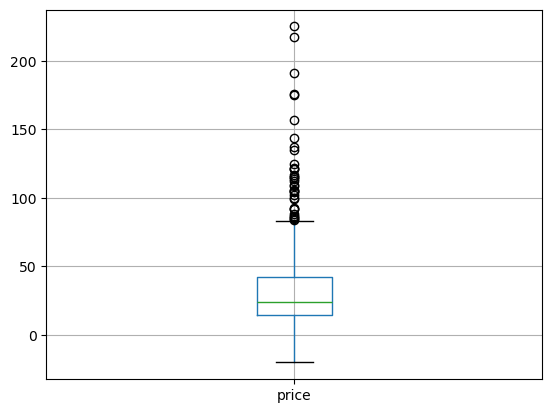

In [64]:
#Création d'une boîte à moustache de la répartition des prix grâce à Pandas

df_merge.boxplot(column=["price"])

In [65]:
#Autre méthode avec plotly express

fig = px.box(df_merge, y="price", labels={"price": "Prix en euros"}, width=600, height=600)
fig.update_layout(
    title={
        'text': "Boîte à moustache variable prix",
        'y':0.94,
        'x':0.5,
        'xanchor': 'center',
        'yanchor': 'top'})
fig.update_layout(
    font=dict(
        family="Arial",
        size=16,  # Set the font size here
        color="Black"))
fig.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2 - Exploration par l'utilisation de méthodes statistiques</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.1 - Identification par le Z-index</h3>
</div>

In [66]:
#Calculer la moyenne du prix

price_mean = df_merge["price"].mean()

#Calculer l'écart-type du prix

price_std = df_merge["price"].std()

#Calculer le Z-score

df_merge["z-score"] = (df_merge["price"] - price_mean) / price_std
df_merge["z-score"] = df_merge["z-score"].round(2)

print("-Moyenne du prix:", round(price_mean,2))
print("-Ecart-type du prix:", round(price_std,2))
print("-Z-score:", round(price_mean/price_std,2))

-Moyenne du prix: 32.19
-Ecart-type du prix: 26.71
-Z-score: 1.2


In [67]:
#Quel est le seuil prix dont le z-score est supérieur à 3?

z_score_sup3 = df_merge[df_merge["z-score"] > 3]
z_score_sup3 = z_score_sup3[['price','z-score']]
z_score3 = z_score_sup3.iloc[-1]['price']

print("-Seuil prix dont le z-score est supérieur à 3:", z_score3)

-Seuil prix dont le z-score est supérieur à 3: 114.0


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.2 - Identification par l'intervalle interquartile</h3>
</div>

In [68]:
#Utilisation de la fonction "describe" de Pandas pour l'étude des mesures de dispersion

price_describe = df_merge.price.describe()
price_describe

count    825.000000
mean      32.187697
std       26.712077
min      -20.000000
25%       14.500000
50%       24.300000
75%       42.000000
max      225.000000
Name: price, dtype: float64

In [69]:
#Définir un seuil pour les articles "outliers" en prix

intervalle_interquartile = price_describe[6] - price_describe[4]

seuil_inferieur = 14.5 - (1.5 * intervalle_interquartile)
seuil_superieur = price_describe[6] + (1.5 * intervalle_interquartile)

print("-Intervalle interquartile:", intervalle_interquartile)
print("-Seuil inférieur:", seuil_inferieur)
print("-Seuil supérieur:", seuil_superieur)

-Intervalle interquartile: 27.5
-Seuil inférieur: -26.75
-Seuil supérieur: 83.25


C:\Users\Ced\AppData\Local\Temp\ipykernel_11836\3519263149.py:3: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`

C:\Users\Ced\AppData\Local\Temp\ipykernel_11836\3519263149.py:6: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



In [70]:
#Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"

df_article_outliers = df_merge[df_merge["price"] > seuil_superieur]
nombre_article_outliers = len(df_article_outliers)

proportion_ensemble_catalogue = nombre_article_outliers / len(df_merge)

print("-Nombre article outliers:", nombre_article_outliers)
print("-Proportion ensemble catalogue:", round(proportion_ensemble_catalogue,3))


-Nombre article outliers: 36
-Proportion ensemble catalogue: 0.044


In [71]:
#Selon vous, ces outliers sont-ils justifiés ? Comment le démontrer si cela est possible ?

df_article_outliers = df_article_outliers[['product_id','price','purchase_price','product_type','post_title']]
df_article_outliers['price_ratio'] = (df_article_outliers['price'] / df_article_outliers['purchase_price']).round(2)
df_article_outliers = df_article_outliers[df_article_outliers['product_type'].notna()]
df_article_outliers


## un ratio entre le prix de vente et d'achat n'indique aucune anomalie avec des valeurs autour de 2
## ces outliers sont justifiés, les prix d'achats sont cohérents il s'agit de vins grands crus, de champagnes, des cognac et whisky haut de gamme
## dans la liste ci-dessous le code 4594 n'est pas affiché car les informations produit sont manquantes

,product_id,price,purchase_price,product_type,post_title,price_ratio
0,4352,225.0,137.81,Champagne,Champagne Egly-Ouriet Grand Cru Millésimé 2008,1.63
1,5001,217.5,116.87,Vin,David Duband Charmes-Chambertin Grand Cru 2014,1.86
2,5892,191.3,116.06,Champagne,Coteaux Champenois Egly-Ouriet Ambonnay Rouge ...,1.65
3,4402,176.0,78.25,Cognac,Cognac Frapin VIP XO,2.25
4,5767,175.0,90.42,Vin,Camille Giroud Clos de Vougeot 2016,1.94
5,4406,157.0,69.08,Cognac,Cognac Frapin Château de Fontpinot 1989 20 Ans...,2.27
7,4904,137.0,67.95,Vin,Domaine Des Croix Corton Charlemagne Grand Cru...,2.02
8,6126,135.0,80.33,Champagne,Champagne Gosset Célébris Vintage 2007,1.68
9,5612,124.8,66.41,Vin,Domaine Weinbach Gewurztraminer Grand Cru Furs...,1.88
10,5917,122.0,54.24,Whisky,Wemyss Malts Single Cask Scotch Whisky Choc 'n...,2.25


In [72]:
df_article_outliers['product_type'].value_counts().sort_index()

### les catégories de produits concernés par les outliers prix sont les champagnes, cognacs, vins et whisky

product_type
Champagne     6
Cognac        4
Vin          19
Whisky        3
Name: count, dtype: int64

In [73]:
#Création d'un dataframe avec le prix moyen par type de produit
table_prix_moyen = pd.pivot_table(df_merge, index=['product_type'], values=['product_id','price'], aggfunc={'product_id':'count','price':'mean'}, margins=True)
table_prix_moyen = table_prix_moyen.reset_index()
table_prix_moyen = table_prix_moyen[table_prix_moyen["product_type"] != "All"]
table_prix_moyen = table_prix_moyen.rename(columns={'price': 'prix_moyen','product_id': 'nombre_article'})
table_prix_moyen = table_prix_moyen.round(1)
table_prix_moyen = table_prix_moyen.sort_values(by=['prix_moyen'],ascending=False)
table_prix_moyen = table_prix_moyen.reset_index(drop=True)
table_prix_moyen

### les catégories de produit Cognac, Whisky, Champagne ont les prix moyens les plus élevés

,product_type,prix_moyen,nombre_article
0,Cognac,97.5,8
1,Champagne,69.6,28
2,Whisky,65.6,14
3,Gin,36.0,2
4,Vin,29.3,658
5,Huile d'olive,24.9,3


In [74]:
## Pour les outliers de la catégorie Vin, 89% des produits sont des Grand Cru ou 1er Cru

df_article_outliers_vin = df_article_outliers[df_article_outliers['product_type'] == 'Vin']
vin_cru_count = (df_article_outliers_vin.post_title.str.count("Cru")).sum()
vin_cru_ratio = vin_cru_count / len(df_article_outliers_vin)
print("-Ratio du nombre de Grand Cru ou 1er Cru dans les outliers prix des vins:",round(vin_cru_ratio,2))

-Ratio du nombre de Grand Cru ou 1er Cru dans les outliers prix des vins: 0.89


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Analyse univariée du CA, des quantités vendues, des stocks et de la marge ainsi qu'une analyse multivariée  </h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.1 - Analyse des ventes en CA</h3>
</div>

In [75]:
##############################
# Calculer le CA du site web #
##############################

#Créer une colonne calculant le CA par article

df_merge["CA_article"] = df_merge["price"] * df_merge["total_sales"]

#Calculer la somme de la colonne "ca_par_article"
#Ce résultat correspond au chiffre d'affaire du site web

chiffre_affaire_web = df_merge["CA_article"].sum()

print("-Chiffre d'affaires web en euros:", chiffre_affaire_web)

-Chiffre d'affaires web en euros: 143680.1


In [76]:
###############################
# Palmarès des articles en CA #
###############################

#Effectuer le tri dans l'ordre décroissant du CA du dataset df_merge

df_merge = df_merge.sort_values(by=['CA_article'], ascending=False)

#Réinitialiser l'index du dataset par un reset_index

df_merge = df_merge.reset_index(drop=True)

#Afficher les 20 premiers articles en CA

df_top20_ca_product = df_merge[:20]

#Graphique en barre des 20 premiers articles avec plotly express

fig = px.bar(df_top20_ca_product, y='CA_article', color="product_type", labels={"CA_article":"CA par article", "index":"Code Produit" },text='product_id')
fig.update_layout(
    title={
        'text': "TOP 20 CA par article",
        'y':0.90,
        'x':0.5,
        'xanchor': 'center',
        'yanchor': 'top'})
fig.update_layout(
    font=dict(
        family="Arial",
        size=16,  # Set the font size here
        color="Black"))
fig.show()

In [77]:
#############################
# Calculer le 20 / 80 en CA #
#############################

#Créer une colonne calculant la part du CA de la ligne dans le dataset

df_merge["CA_article_pourcent"] = df_merge["CA_article"] / chiffre_affaire_web
df_merge["CA_article_pourcent"] = df_merge["CA_article_pourcent"].round(4)

#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée

df_merge["CA_article_cumul"]  = df_merge["CA_article_pourcent"].cumsum()
df_merge["CA_article_cumul"] = df_merge["CA_article_cumul"].round(4)

#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% du CA

df_merge['CA_article_2080'] = df_merge['CA_article_cumul'].apply(lambda x: 1 if x <= 0.8 else 0)
nb_2080_ca_catalogue =  df_merge["CA_article_2080"].sum()

#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web

proportion_2080_ca_catalogue = nb_2080_ca_catalogue / len(df_merge)

print("-Nombre produits 20/80 CA:",nb_2080_ca_catalogue)
print("-Proportion 20/80 CA catalogue:",round(proportion_2080_ca_catalogue,3))

-Nombre produits 20/80 CA: 433
-Proportion 20/80 CA catalogue: 0.525


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.2 - Analyse des ventes en quantité</h3>
</div>

In [78]:
#####################################
# Palmarès des articles en quantité #
#####################################

#Effectuer le tri dans l'ordre décroissant de quantités vendues du dataset df_merge

df_merge = df_merge.sort_values(by=['total_sales'], ascending=False)

#Réinitialiser l'index du dataset par un reset_index

df_merge.reset_index(drop=True)

#Afficher les 20 premiers articles en quantité

df_top20_ventes_product = df_merge[:20]

#Graphique en barre des 20 premiers articles avec plotly express

df_top20_ventes_product = df_merge[['product_id','total_sales','product_type']]
df_top20_ventes_product = df_top20_ventes_product.reset_index(drop=True)
df_top20_ventes_product = df_top20_ventes_product.iloc[0:20]

fig = px.bar(df_top20_ventes_product, y='total_sales', color="product_type", labels={"total_sales":"Ventes par article", "index":"Code Produit" },text='product_id')
fig.update_layout(
    title={
        'text': "TOP 20 ventes par article",
        'y':0.90,
        'x':0.5,
        'xanchor': 'center',
        'yanchor': 'top'})
fig.update_layout(
    font=dict(
        family="Arial",
        size=16,  # Set the font size here
        color="Black"))
fig.show()

In [79]:
#############################
# Calculer le 20 / 80 en CA #
#############################

#Créer une colonne calculant la part en quantité de la ligne dans le dataset

df_merge = df_merge.sort_values(by=['total_sales'], ascending=False)
df_merge.reset_index(drop=True)
df_merge["total_sales_pourcent"] = df_merge["total_sales"] / df_merge["total_sales"].sum()
df_merge["total_sales_pourcent"] = df_merge["total_sales_pourcent"].round(4)

#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée

df_merge["total_sales_cumul"]  = df_merge["total_sales_pourcent"].cumsum()
df_merge["total_sales_cumul"] = df_merge["total_sales_cumul"].round(4)

#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% des ventes en quantité

df_merge['total_sales_2080'] = df_merge['total_sales_cumul'].apply(lambda x: 1 if x <= 0.8 else 0)
nb_2080_quantite_catalogue = df_merge["total_sales_2080"].sum()

#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web

proportion_2080_quantite_catalogue = nb_2080_quantite_catalogue / len(df_merge)

print("-Nombre produits 20/80 quantité:",nb_2080_quantite_catalogue)
print("-Proportion 20/80 quantité catalogue:",round(proportion_2080_quantite_catalogue,3))

-Nombre produits 20/80 quantité: 432
-Proportion 20/80 quantité catalogue: 0.524


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.3 - Analyse des stocks</h3>
</div>

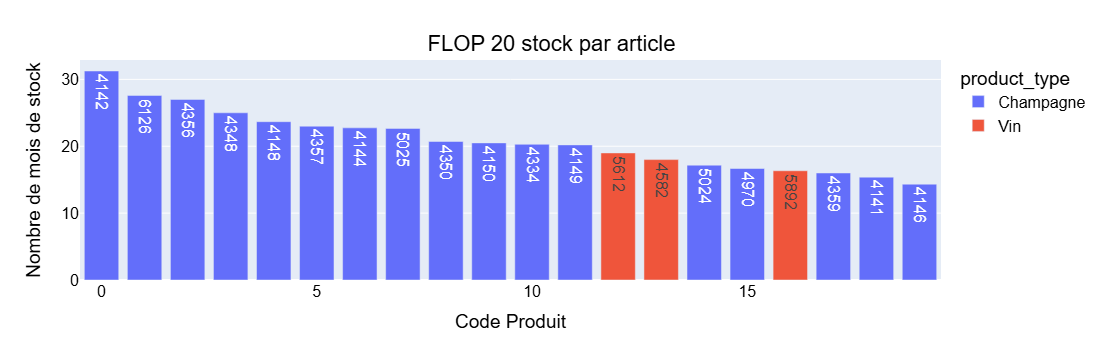

In [104]:
######################################
# Calculer le nombre de mois de stock #
######################################

#Import de numpy 

import numpy as np

#Création de la colonne Rotation de stock

df_merge['rotation_stock'] = df_merge["stock_quantity"] / df_merge['total_sales']
df_merge["rotation_stock"] = df_merge["rotation_stock"].round(2)

#Remplacement des "inf" par 0

df_merge.replace([np.inf, -np.inf], 0, inplace=True)

#Effectuer le tri dans l'ordre décroissant du nombre de mois de stock dans le dataset df_merge

df_merge = df_merge.sort_values(by=['rotation_stock'], ascending=False)
#df_merge

#Graphique en barre du flop 20 des produits qui ont le plus de mois de stock

df_flop20_stock = df_merge[['product_id','rotation_stock','product_type']]
df_flop20_stock = df_flop20_stock.reset_index(drop=True)
df_flop20_stock = df_flop20_stock.iloc[0:20]

fig = px.bar(df_flop20_stock, y='rotation_stock', color="product_type", labels={"rotation_stock":"Nombre de mois de stock", "index":"Code Produit" },text="product_id")
fig.update_layout(
    title={
        'text': "FLOP 20 stock par article",
        'y':0.90,
        'x':0.5,
        'xanchor': 'center',
        'yanchor': 'top'})
fig.update_layout(
    font=dict(
        family="Arial",
        size=16,  # Set the font size here
        color="Black"))
fig.show()

## il y a 17 produits de la famille champagne sur le top 20, ce stock est probablement présent en raison des ventes liées aux fêtes de fin d'année

In [81]:
"""
Il y a 3 produits (product_id : 4337/4355/5932) ayant du stock mais sans ventes, ils n'apparaissent pas dans ce flop 20 mais sont à prendre en compte pour
une analyse des problématiques stock par produit (2 produits sont des champagnes ayant un prix d'achat élevé et des quantités importantes en stock).

"""

"\nIl y a 3 produits (product_id : 4337/4355/5932) ayant du stock mais sans ventes, ils n'apparaissent pas dans ce flop 20 mais sont à prendre en compte pour\nune analyse des problématiques stock par produit (2 produits sont des champagnes ayant un prix d'achat élevé et des quantités importantes en stock).\n\n"

In [82]:
####################################
# Valorisation des stocks en euros #
####################################

#Création de la colonne Valorisation des stocks en euros

df_merge['valorisation_stock'] = df_merge['stock_quantity'] * df_merge['price']

#Calculer la somme de la colonne "Valorisation_stock_euros"

somme_valorisation_stock = df_merge['valorisation_stock'].sum()

print("-Somme valorisation du stock en euros:",round(somme_valorisation_stock,2))
print("-Nombre de mois de stock total:",round(somme_valorisation_stock / chiffre_affaire_web,2))

-Somme valorisation du stock en euros: 531628.8
-Nombre de mois de stock total: 3.7


In [83]:
##############################################
# Valorisation du nombre de produits en stock #
##############################################

#Calculer la somme de la colonne stock quantity

somme_stock_quantity = df_merge['stock_quantity'].sum()

print("-Somme quantité stock:",somme_stock_quantity)

-Somme quantité stock: 17811


In [84]:
## Nous avons également des problématiques potentielles de cohérence entre le statut de vente en ligne (onsale_web) et les ventes
## Il serait souhaitable de vérifier les éventuels erreurs de référentiel ou SI 

## 1 produit qui n'est pas en vente sur le site web avec des quantités écoulées
## 3 produits qui sont en vente sur le site mais sans quantités vendues (1 produit champagne a un prix de vente en erreur de saisie)

In [85]:
df_onsale_web0 = df_merge[df_merge['onsale_web'] == 0]
df_onsale_web0 = df_onsale_web0[df_onsale_web0['total_sales'] > 0]
df_onsale_web0

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,total_sales,product_type,post_title,post_name,z-score,CA_article,CA_article_pourcent,CA_article_cumul,CA_article_2080,total_sales_pourcent,total_sales_cumul,total_sales_2080,rotation_stock,valorisation_stock
663,4200,0,5.8,33,instock,3.12,16295.0,14.0,Vin,Moulin de Gassac IGP Pays d'Hérault Guilhem Ro...,moulin-de-gassac-igp-pays-dherault-guilhem-ros...,-0.99,81.2,0.0006,0.9902,0,0.0024,0.1249,1,2.36,191.4


In [86]:
df_onsale_web1 = df_merge[df_merge['onsale_web'] == 1]
df_onsale_web1 = df_onsale_web1[df_onsale_web1['total_sales'] == 0]
df_onsale_web1 = df_onsale_web1[df_onsale_web1['stock_status'] == 'instock']
df_onsale_web1

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,total_sales,product_type,post_title,post_name,z-score,CA_article,CA_article_pourcent,CA_article_cumul,CA_article_2080,total_sales_pourcent,total_sales_cumul,total_sales_2080,rotation_stock,valorisation_stock
695,4337,1,83.00,145,instock,48.90,4679.0,0.0,Champagne,Champagne Mailly Grand Cru Les Echansons 2007,champagne-mailly-grand-cru-les-echansons-2007,1.90,0.0,0.0,1.0012,0,0.0,0.9984,0,0.0,12035.00
690,4355,1,12.65,97,instock,77.48,12589.0,0.0,Champagne,Champagne Egly-Ouriet Grand Cru Blanc de Noirs,champagne-egly-ouriet-grand-cru-brut-blanc-de-...,-0.73,0.0,0.0,1.0012,0,0.0,0.9984,0,0.0,1227.05
704,5932,1,59.90,13,instock,27.18,523.0,0.0,Cognac,Cognac Normandin Mercier VFC,cognac-normandin-mercier-vfc,1.04,0.0,0.0,1.0012,0,0.0,0.9984,0,0.0,778.70


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Analyse du taux de marge</h3>
</div>

In [87]:
############################
# Analyse du taux de marge #
############################

#Création de la colonne Prix HT

df_merge['prix_ht'] = df_merge['price'] / (1 + 0.2)
df_merge["prix_ht"] = df_merge["prix_ht"].round(3)

#Création de la colonne Taux de marge

df_merge['taux_marge'] = (df_merge['prix_ht'] - df_merge['purchase_price']) / df_merge['prix_ht']
df_merge["taux_marge"] = df_merge["taux_marge"].round(3)

#Afficher le prix minimum de la colonne "taux_marge"

marge_minimum = df_merge['taux_marge'].min()

print("-Marge_minimum:",round(marge_minimum,3))

#Afficher le prix maximum de la colonne "taux_marge"

marge_maximum = df_merge['taux_marge'].max()

print("-Marge_maximum:",round(marge_maximum,3))

-Marge_minimum: -6.35
-Marge_maximum: 1.651


In [88]:
#Affichage de la ligne avec un taux de marge inférieur à 0

df_marge_negative = df_merge[df_merge['taux_marge'] < 0]
df_marge_negative

## Il y a 4 lignes en marge négative
## la ligne product_id 4355 contient une erreur de saisie, d'après le taux de marge moyen le prix d'achat devrait être de 126,5 et non de de 12,65
## les trois autres lignes sont des erreurs de saisie de prix de vente avec une non prise en compte de la notion de vente à perte

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,total_sales,product_type,post_title,post_name,z-score,CA_article,CA_article_pourcent,CA_article_cumul,CA_article_2080,total_sales_pourcent,total_sales_cumul,total_sales_2080,rotation_stock,valorisation_stock,prix_ht,taux_marge
690,4355,1,12.65,97,instock,77.48,12589.0,0.0,Champagne,Champagne Egly-Ouriet Grand Cru Blanc de Noirs,champagne-egly-ouriet-grand-cru-brut-blanc-de-...,-0.73,0.0,0.0,1.0012,0,0.0,0.9984,0,0.0,1227.05,10.542,-6.350
715,6324,0,92.00,18,instock,99.00,NaN,NaN,NaN,NaN,NaN,2.24,NaN,NaN,NaN,0,NaN,NaN,0,NaN,1656.00,76.667,-0.291
762,7196,0,31.00,55,instock,31.20,NaN,NaN,NaN,NaN,NaN,-0.04,NaN,NaN,NaN,0,NaN,NaN,0,NaN,1705.00,25.833,-0.208
821,4864,0,8.30,0,outofstock,9.99,15154.0,NaN,NaN,NaN,NaN,-0.89,NaN,NaN,NaN,0,NaN,NaN,0,NaN,0.00,6.917,-0.444


In [89]:
#Création d'un dataframe avec les taux positifs

df_marge_positive = df_merge[df_merge['taux_marge'] > 0]
#df_marge_positive

#Afficher le prix minimum de la colonne "taux_marge"

prix_minimum_tx_marge  = df_marge_positive['taux_marge'].min()
print("-Marge_minimum:",round(prix_minimum_tx_marge,3))

#Afficher le prix maximum de la colonne "taux_marge"

prix_maximum_tx_marge = df_marge_positive['taux_marge'].max()
print("-Marge_minimum:",round(prix_maximum_tx_marge,3))

-Marge_minimum: 0.228
-Marge_minimum: 1.651


In [90]:
## Vérification et modification des attributions des types de produit

df_merge['product_type'].value_counts().sort_index()

product_type
Champagne         28
Cognac             8
Gin                2
Huile d'olive      3
Vin              658
Whisky            14
Name: count, dtype: int64

In [91]:
# Modification du type produit pour les lignes non attribuées correctement

df_merge['product_type'] = np.where((df_merge['product_id'] == 4954), 'Autre', df_merge['product_type'])
df_merge['post_title'] = np.where((df_merge['post_title'] == 4954), 'Bon cadeau de 25€', df_merge['post_title'])
df_merge['product_type'] = np.where((df_merge['product_id'] == 5892), 'Vin', df_merge['product_type'])
df_merge['product_type'] = np.where( ((df_merge['product_id'] >= 4625) & (df_merge['product_id'] <= 4636)), 'Eau de vie', df_merge['product_type'])

In [92]:
df_merge['product_type'].value_counts().sort_index()

product_type
Autre              1
Champagne         27
Cognac             8
Eau de vie        12
Gin                2
Huile d'olive      3
Vin              647
Whisky            14
Name: count, dtype: int64

In [93]:
#Création d'un dataframe avec le taux de marge moyen par type de produit
df_marge_positive = df_merge[df_merge['taux_marge'] > 0]
table_tx_marge_moyen = pd.pivot_table(df_marge_positive, index=['product_type'], values=['product_id','taux_marge'], aggfunc={'product_id':'count','taux_marge':'mean'}, margins=True)
table_tx_marge_moyen = table_tx_marge_moyen.reset_index()
table_tx_marge_moyen = table_tx_marge_moyen[table_tx_marge_moyen["product_type"] != "All"]
table_tx_marge_moyen = table_tx_marge_moyen.round(3)
table_tx_marge_moyen

,product_type,product_id,taux_marge
0,Autre,1,0.362
1,Champagne,26,0.285
2,Cognac,8,0.450
3,Eau de vie,12,0.378
4,Gin,2,0.428
5,Huile d'olive,3,0.250
6,Vin,647,0.380
7,Whisky,14,0.449


In [94]:
#Affichage dans un graphique du taux de marge par type de produit

fig = px.bar(table_tx_marge_moyen, x='product_type', y='taux_marge', text_auto=True, labels={"product_type":"Type de produit", "taux_marge":"Taux de marge" })
fig.update_layout(
    title={
        'text': "Taux de marge par type de produit",
        'y':0.90,
        'x':0.5,
        'xanchor': 'center',
        'yanchor': 'top'})
fig.update_layout(
    font=dict(
        family="Arial",
        size=16,  # Set the font size here
        color="Black"))
fig.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.5 - Analyse des corrélations entre les variables stock, sales et price</h3>
</div>

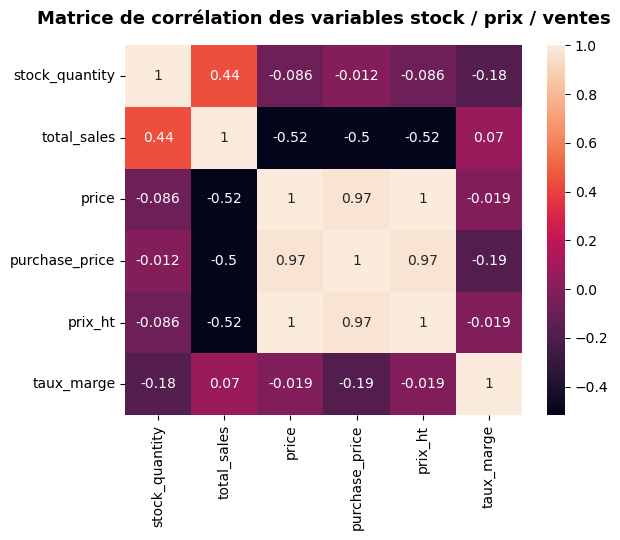

In [95]:
############################
# Analyse des corrélations #
############################

#Importation de Seaborn

import seaborn as sns
import matplotlib.pyplot as plt

#Création d'une heatmap de corrélation avec les variables stock, sales et price
#On peut également créer un mask pour n'afficher qu'une demi heatmap

# load the Auto dataset
corr_df = df_merge[['stock_quantity','total_sales','price','purchase_price','prix_ht','taux_marge']]

# calculate the correlation matrix on the numeric columns
corr = corr_df.corr()
#corr

# plot the heatmap
sns.heatmap(corr, annot=True)
plt.title("Matrice de corrélation des variables stock / prix / ventes", fontsize = 13, weight='bold', pad=15, loc = 'center')
plt.show()

In [96]:
#Que peut-on conclure des corrélations ?
"""
Il y a plusieurs corrélations à considérer :

1-La corrélation entre quantité de stock et ventes est de 0,44 ; forte et positive (la quantité de stock est élevée quand les ventes sont fortes)
2-La corrélation entre quantité de stock et taux de marge est de -0,18 ; moyenne et négative (la quantité de stock est élevée quand la marge est faible)
3-La corrélation entre quantité de stock et prix est de -0,086 ; faible et négative

4-La corrélation entre prix et ventes est de -0,52 ; forte et négative (plus le prix est élevé, plus les ventes sont faibles) 
5-La corrélation entre prix et prix d'achat est de 0,97 ; très forte et positive (plus le prix d'achat est élevé, plus le prix de vente est élevé) 
6-La corrélation entre prix et taux de marge est de -0,019 ; très faible et négative

"""

"\nIl y a plusieurs corrélations à considérer :\n\n1-La corrélation entre quantité de stock et ventes est de 0,44 ; forte et positive (la quantité de stock est élevée quand les ventes sont fortes)\n2-La corrélation entre quantité de stock et taux de marge est de -0,18 ; moyenne et négative (la quantité de stock est élevée quand la marge est faible)\n3-La corrélation entre quantité de stock et prix est de -0,086 ; faible et négative\n\n4-La corrélation entre prix et ventes est de -0,52 ; forte et négative (plus le prix est élevé, plus les ventes sont faibles) \n5-La corrélation entre prix et prix d'achat est de 0,97 ; très forte et positive (plus le prix d'achat est élevé, plus le prix de vente est élevé) \n6-La corrélation entre prix et taux de marge est de -0,019 ; très faible et négative\n\n"

In [97]:
#Création d'un dataframe avec le CA par type de produit
table_ca_type = pd.pivot_table(df_merge, index=['product_type'], values=['CA_article'], aggfunc='sum', margins=True)
table_ca_type = table_ca_type.reset_index()
table_ca_type = table_ca_type[table_ca_type["product_type"] != "All"]
table_ca_type = table_ca_type.round(0)
table_ca_type

#Affichage dans un graphique du taux de marge par type de produit
fig = px.bar(table_ca_type, x='product_type', y='CA_article', text_auto=True, labels={"product_type":"Type de produit", "CA_article":"CA en €" })
fig.update_layout(
    title={
        'text': "CA par type de produit",
        'y':0.90,
        'x':0.5,
        'xanchor': 'center',
        'yanchor': 'top'})
fig.update_layout(
    font=dict(
        family="Arial",
        size=16,  # Set the font size here
        color="Black"))
fig.show()

In [98]:
#Création d'un dataframe avec le stock par type de produit
table_stock_type = pd.pivot_table(df_merge, index=['product_type'], values=['valorisation_stock'], aggfunc='sum', margins=True)
table_stock_type = table_stock_type.reset_index()
table_stock_type = table_stock_type[table_stock_type["product_type"] != "All"]
table_stock_type = table_stock_type.round(0)
table_stock_type

#Affichage dans un graphique du stock par type de produit
fig = px.bar(table_stock_type, x='product_type', y='valorisation_stock', text_auto=True, labels={"product_type":"Type de produit", "valorisation_stock":"Valeur de stock en €" })
fig.update_layout(
    title={
        'text': "Stock par type de produit",
        'y':0.90,
        'x':0.5,
        'xanchor': 'center',
        'yanchor': 'top'})
fig.update_layout(
    font=dict(
        family="Arial",
        size=16,  # Set the font size here
        color="Black"))
fig.show()

In [99]:
## Création d'une colonne catégorie de prix

df_merge['price_category'] = np.trunc(df_merge['price'] / 10)
df_merge['price_category'] = np.where( df_merge['price'] < 10,  0, df_merge['price_category'])
df_merge['price_category'].value_counts().sort_index()

price_category
0.0      79
1.0     254
2.0     170
3.0      94
4.0      93
5.0      48
6.0      26
7.0      23
8.0       8
9.0       4
10.0      8
11.0      5
12.0      4
13.0      2
14.0      1
15.0      1
17.0      2
19.0      1
21.0      1
22.0      1
Name: count, dtype: int64

In [100]:
## Tableau récapitulatif du CA et valorisation stock, et les pourcentages correspondants par catégorie prix
## Mise en avant de différences entre les catégories de prix

table_price_category = pd.pivot_table(df_merge, index=['product_type','price_category'], values=['product_id','CA_article','valorisation_stock','rotation_stock'], aggfunc={'product_id':'count','CA_article':'sum','valorisation_stock':'sum','rotation_stock':'mean'}, margins=True)
table_price_category = table_price_category.reset_index()
table_price_category = table_price_category[table_price_category["product_type"] == "Vin"]
table_price_category['pourcentage_ca'] = table_price_category['CA_article'] / table_price_category['CA_article'].sum()
table_price_category['pourcentage_stock'] = table_price_category['valorisation_stock'] / table_price_category['valorisation_stock'].sum()
table_price_category['pourcentage_ecart'] = table_price_category['pourcentage_stock'] - table_price_category['pourcentage_ca']
table_price_category = table_price_category[['product_type','price_category','product_id','CA_article','valorisation_stock','pourcentage_ca','pourcentage_stock','pourcentage_ecart','rotation_stock']]
table_price_category = table_price_category.round(3)
table_price_category = table_price_category.reset_index(drop=True)
table_price_category

,product_type,price_category,product_id,CA_article,valorisation_stock,pourcentage_ca,pourcentage_stock,pourcentage_ecart,rotation_stock
0,Vin,0.0,75,7835.30,21277.70,0.064,0.071,0.007,2.713
1,Vin,1.0,230,34481.75,92010.15,0.282,0.309,0.027,2.683
2,Vin,2.0,136,26906.75,71879.40,0.220,0.241,0.021,2.661
3,Vin,3.0,63,13524.30,20443.30,0.111,0.069,-0.042,1.520
4,Vin,4.0,56,13774.90,19021.30,0.113,0.064,-0.049,1.384
5,Vin,5.0,30,6861.10,10259.20,0.056,0.034,-0.022,1.487
6,Vin,6.0,19,5279.70,8417.70,0.043,0.028,-0.015,1.565
7,Vin,7.0,17,4799.40,7453.90,0.039,0.025,-0.014,1.546
8,Vin,8.0,3,769.40,1113.60,0.006,0.004,-0.003,1.467
9,Vin,9.0,2,686.00,891.00,0.006,0.003,-0.003,0.750


In [101]:
## Graphique de visualisation des pourcentages de CA et valorisation stock par segment de prix
fig = px.bar(table_price_category, x="price_category", y=["pourcentage_ca","pourcentage_stock","pourcentage_ecart"], labels={"price_category":"Catégorie de produit"},barmode="group")
fig.update_layout(
    title={
        'text': "Pourcentage de CA total et valorisation de stock par segment de prix de la catégorie Vins",
        'y':0.90,
        'x':0.5,
        'xanchor': 'center',
        'yanchor': 'top'})
fig.update_layout(
    font=dict(
        family="Arial",
        size=16,  # Set the font size here
        color="Black"))
fig.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.6 - Mise à disposition de la nouvelle table sur un fichier Excel</h3>
</div>

In [102]:
df_merge.info()

<class 'pandas.core.frame.DataFrame'>
Index: 825 entries, 240 to 824
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   product_id            825 non-null    int64  
 1   onsale_web            825 non-null    int64  
 2   price                 825 non-null    float64
 3   stock_quantity        825 non-null    int64  
 4   stock_status          825 non-null    object 
 5   purchase_price        825 non-null    float64
 6   id_web                734 non-null    float64
 7   total_sales           714 non-null    float64
 8   product_type          714 non-null    object 
 9   post_title            714 non-null    object 
 10  post_name             714 non-null    object 
 11  z-score               825 non-null    float64
 12  CA_article            714 non-null    float64
 13  CA_article_pourcent   714 non-null    float64
 14  CA_article_cumul      714 non-null    float64
 15  CA_article_2080       825 

In [103]:
#Mettre le dataset df_merge sur un fichier Excel
#Cette étape peut être utile pour partager le résultat du dataset obtenu avec les équipes.  

df_merge = df_merge.sort_values(by=['product_id'])
df_merge = df_merge.reset_index(drop=True)

df_merge.to_excel("df_merge.xlsx")